# Json

In [68]:
import json
import pprint
import numpy as np
import matplotlib
import sys
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
import umap
from matplotlib import pyplot as plt


In [2]:
import json
with open(
    r"C:\Users\ACER\Desktop\UNIVERSITAS DOCTUS\Notas OneNote\Programación\Tesis\Encoder-xAI-LLMs\data\raw\Experimento.json",
    encoding="utf-8"
 ) as f:
 corpus=json.load(f)
 print(len(corpus))

30


In [3]:
from pprint import pprint
pprint(corpus[0])

{'DOI': '10.18653/v1/D17-1042',
 'URL': 'https://aclanthology.org/D17-1042/',
 'abstract': 'We interpret the predictions of any black-box structured '
             'input-structured output model around a specific input-output '
             'pair. Our method returns an “explanation” consisting of groups '
             'of input-output tokens that are causally related. These '
             'dependencies are inferred by querying the model with perturbed '
             'inputs, generating a graph over tokens from the responses, and '
             'solving a partitioning problem to select the most relevant '
             'components. We focus the general approach on '
             'sequence-to-sequence problems, adopting a variational '
             'autoencoder to yield meaningful input perturbations. We test our '
             'method across several NLP sequence generation tasks.',
 'accessed': {'date-parts': [['2026', 6, 12]]},
 'author': [{'family': 'Alvarez-Melis', 'given': 'David'},


# Librerías
Solo para cuando estoy trabajando con python 3.14

In [16]:
import sys
print(sys.executable)
!{sys.executable} -m pip show pandas
!{sys.executable} -m pip install pandas

c:\Users\ACER\AppData\Local\Python\pythoncore-3.14-64\python.exe


  Using cached tzdata-2026.2-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ----------- ---------------------------- 2.9/9.9 MB 19.1 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.9 MB 25.0 MB/s eta 0:00:01
   ---------------------------------------- 9.9/9.9 MB 22.7 MB/s  0:00:00
Using cached tzdata-2026.2-py2.py3-none-any.whl (349 kB)

   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   ----


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Experimentos

In [3]:
import pandas as pd

df = pd.DataFrame({
    "title": [x.get("title","") for x in corpus],
    "abstract": [x.get("abstract","") for x in corpus],
    "year": [
        x.get("issued",{})
         .get("date-parts",[[""]])[0][0]
        for x in corpus
    ],
    "doi": [x.get("DOI","") for x in corpus]
})
df.head()

,title,abstract,year,doi
0,A causal framework for explaining the predicti...,We interpret the predictions of any black-box ...,2017,10.18653/v1/D17-1042
1,Naturalistic Causal Probing for Morpho-Syntax,Probing has become a go-to methodology for int...,2023,10.1162/tacl_a_00554
2,On the Pitfalls of Analyzing Individual Neuron...,While many studies have shown that linguistic ...,2021,
3,Challenges in Applying Explainability Methods ...,Motivations for methods in explainable artific...,2022,10.48550/arXiv.2206.03945
4,"Probing Classifiers: Promises, Shortcomings, a...",Probing classifiers have emerged as one of the...,2022,10.1162/coli_a_00422


In [56]:
df[:]["title"]

0     A causal framework for explaining the predicti...
1         Naturalistic Causal Probing for Morpho-Syntax
2     On the Pitfalls of Analyzing Individual Neuron...
3     Challenges in Applying Explainability Methods ...
4     Probing Classifiers: Promises, Shortcomings, a...
5     Eliciting Latent Predictions from Transformers...
6     Contextualization and Exploration of Local Fea...
7     e-SNLI: Natural Language Inference with Natura...
8     Transformer Interpretability Beyond Attention ...
9     Interpreting Randomly Wired Graph Models for C...
10    Explaining non-linear Classifier Decisions wit...
11            Analyzing Transformers in Embedding Space
12    Amnesic Probing: Behavioral Explanation with A...
13    Measuring Causal Effects of Data Statistics on...
14    Sequential Integrated Gradients: a simple but ...
15    CausaLM: Causal Model Explanation Through Coun...
16    Pathologies of Neural Models Make Interpretati...
17    Causal Analysis of Syntactic Agreement Mec

In [9]:
df.info()
df.isna().sum()
len(df[df["abstract"].notna()])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   title     30 non-null     object
 1   abstract  30 non-null     object
 2   year      30 non-null     object
 3   doi       30 non-null     object
dtypes: object(4)
memory usage: 1.1+ KB


30

In [5]:
df["text"]=(df["title"]+"."+df["abstract"])
# Junta el titulo con el abstract porque muchas veces el título tiene información muy discriminativa.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   title     30 non-null     object
 1   abstract  30 non-null     object
 2   year      30 non-null     object
 3   doi       30 non-null     object
 4   text      30 non-null     object
dtypes: object(5)
memory usage: 1.3+ KB


# Transformer

In [6]:
from sentence_transformers import SentenceTransformer
model=SentenceTransformer(
    "all-MiniLM-L6-v2"
)
# Instancia el modelo.
embeddings=model.encode( # Genera los embeddings.
    df["text"].tolist(),
    # como df es de pandas al extraer una columna te devuelve un objeto pandas.core.series (serie de pandas [lista con indices])
    # Queremos que la lista con indices se convierta solo en una lista ["asd","asd"]
    # El método model.encode() esta diseñado para recibir str o list[str]
    show_progress_bar=True
)
# 1 Tokenizar. El texto entra al tokenizer (se fragmenta y se asigna un identificador numérico a cada fragmento)
# 2 Vectorizar. El encoder produce representaciones. El transformer genera un vector para cada token (código de identificación)
# 3 Atención y contexto. Después de varias capas "causal" no tiene la misma representación que "causal inference". Los demás tokens modifican su vector mediante atención.
# 4 Pooling. En (2-3) se trabaja a nivel token, En (4) "promediamos" para tener un único vector para todo el artículo?
# 5 Proyección. Agrupa todo en una matriz (30, 384). Cada elemento tiene un vector de 384 dimensiones cuyo significado desconocemos.
embeddings.shape

Batches: 100%|██████████| 1/1 [00:00<00:00,  1.22it/s]


(30, 384)

model.encode([t1,t2,t3]) Dice que se tiene que procesar la secuencia A, secuencia B, secuencia C. No dice que A es un artículo, B es una oración o C un argumento. La clave está en qué recibe encode. Siempre te devolverá un vector por una secuencia.

Una prueba interesante sería tomar uno de los artículos y fragmentarlo en título, abstract y título_abstract para generar embeddings por separado y comparar la similitud coseno en cada caso.

In [30]:
titulo=df["title"][0]
abst=df['abstract'][0]
titabs=df['text'][0]
todo=titulo,abst,titabs
emb_sep=model.encode(todo,show_progress_bar=True)


#print(titulo)
#print(abst)
#print(titabs)


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  4.15it/s]


In [36]:
from sklearn.metrics.pairwise import cosine_similarity
# print(emb_sep[0])

sim1=cosine_similarity(emb_sep)
#print(sim1)
labels = ["titulo", "abstract", "titulo+abstract"]

for i in range(3):
    for j in range(3):
        print(
            labels[i],
            "vs",
            labels[j],
            "=",
            round(sim1[i][j],3)
        )

titulo vs titulo = 1.0
titulo vs abstract = 0.602
titulo vs titulo+abstract = 0.677
abstract vs titulo = 0.602
abstract vs abstract = 1.0
abstract vs titulo+abstract = 0.971
titulo+abstract vs titulo = 0.677
titulo+abstract vs abstract = 0.971
titulo+abstract vs titulo+abstract = 1.0


# Similitudes con referencia

In [25]:
from sklearn.metrics.pairwise import cosine_similarity

sim = cosine_similarity(embeddings)
# Mide el ángulo entre dos puntos del espacio semántico.
# En embeddings suele importar más la dirección semántica que la distancia.
# sim es un objeto tipo <class 'numpy.ndarray'> de dimensión (30, 30)
# Hay 30 vectores, cada uno con 1 vector de 30 unidades.
# En el vector 1 hay un vector de 30 dimensiones. En la 1,1 está el ángulo entre ellos. En 1,2 el ángulo entre ellos.
sim.shape
# en sim[0] tengo como se compara el articulo 1 con todos los demas (y consigo mismo.)
print(type(sim[0]))
print(sim[0])

<class 'numpy.ndarray'>
[1.         0.5800825  0.35436618 0.377025   0.4626971  0.58647704
 0.25551444 0.48901224 0.3908039  0.3829332  0.49393767 0.48312747
 0.5089818  0.62069327 0.5755639  0.679073   0.54012215 0.5354003
 0.4511011  0.33217865 0.5408231  0.4158393  0.57528305 0.47324312
 0.46429724 0.34996688 0.27047393 0.47728956 0.523111   0.5892459 ]


In [ ]:
df.iloc[0]["title"]

In [8]:
import numpy as np

indices = np.argsort(sim[0])[::-1]

indices[:10]

array([ 0, 15, 13, 29,  5,  1, 14, 22, 20, 16])

In [15]:
for i in indices[:10]:
    print()
    print(round(sim[0][i],3))
    print(df.iloc[i]["title"])


1.0
A causal framework for explaining the predictions of black-box sequence-to-sequence models

0.679
CausaLM: Causal Model Explanation Through Counterfactual Language Models

0.621
Measuring Causal Effects of Data Statistics on Language Model's `Factual' Predictions

0.589
LIREx: Augmenting Language Inference with Relevant Explanations

0.586
Eliciting Latent Predictions from Transformers with the Tuned Lens

0.58
Naturalistic Causal Probing for Morpho-Syntax

0.576
Sequential Integrated Gradients: a simple but effective method for explaining language models

0.575
Evaluating neural network explanation methods using hybrid documents and morphosyntactic agreement

0.541
GeoSteer: Faithful Chain-of-Thought Steering via Latent Manifold Gradients

0.54
Pathologies of Neural Models Make Interpretations Difficult


In [39]:
idx = df[df["title"].str.contains("Probing Classifiers")].index[0]
# Busca "Probing Classifiers" en títulos del df y obtiene lista booleana.
# Busca la lista booleana, encuentra un elemento y extrae el índice de ese elemento.
# idx cotniene el índice del artículo de referencia..
indices = np.argsort(sim[idx])[::-1] 
# sim es el resultado de cosine_similarities(embeddings). Es una matriz (30,30)
# El orden de sim es el mismo que el df. Cada fila de sim tiene los mismos indices que df.
# en sim[0] tengo como se compara el articulo 1 con todos los demas (y consigo mismo)
# Uso el índice idx para obtener la similitud respecto del articulo numero idx (referencia).
# [::-1] Invierte el orden de los valores por grado de similitud
# Argsort no devuelve los valores, devuelve los índices ordenados por grado de similitud.
#print(indices)
for i in indices[:10]:
    # Ciclo que recorre los 10 más similares.
    print(round(sim[idx][i],3)) # i es el indice en indices que ya está ordenado.
    # Round redondea.
    print(df.iloc[i]["title"])

[ 4  1 12 16  2 18 11 22 10  9 17 24 15  5 23 13 21 14 29  3  0  8 28  7
 27 20 25  6 26 19]
1.0
Probing Classifiers: Promises, Shortcomings, and Advances
0.643
Naturalistic Causal Probing for Morpho-Syntax
0.602
Amnesic Probing: Behavioral Explanation with Amnesic Counterfactuals
0.601
Pathologies of Neural Models Make Interpretations Difficult
0.599
On the Pitfalls of Analyzing Individual Neurons in Language Models
0.595
DeepDecipher: Accessing and Investigating Neuron Activation in Large Language Models
0.595
Analyzing Transformers in Embedding Space
0.558
Evaluating neural network explanation methods using hybrid documents and morphosyntactic agreement
0.555
Explaining non-linear Classifier Decisions within Kernel-based Deep Architectures
0.536
Interpreting Randomly Wired Graph Models for Chinese NER


# kmeans
Cluster por Kmeans

A diferencia de "centro del campo" no supone que haya un solo centro, sino que supone que hay varios.
Intenta responder ¿Qué familia de artículos existen? ¿Qué diferencias internas hay?

Formalmente calcula $\sum_i ||x_i-c_i||^2$ donde
- $x_i$ es el embedding del articulo
- $c_i$ es el centroide de su cluster.

In [ ]:
from sklearn.cluster import KMeans
kmeans=KMeans(n_clusters=4,random_state=42)
df["cluster"]=kmeans.fit_predict(embeddings)
# Crea una columna cluster cuyo valor esta entre 0-3 (los n_clusters)
for c in sorted(df["cluster"].unique()):
    print("\nCLUSTER", c)

    subset = df[df["cluster"]==c]

    for titulo in subset["title"]:
        print("-", titulo)

kmeans.fit_predict(embeddings)

combina 2 operaciones:
1. fit. Primero K-means aprende los clusters.
    - kmeans.fit(embeddings)
    - Observa todos los embeddings e intenta encontrar 4 centroides (porque pusiste n_clusters=4)
2. predict()
    - kmeans.predict(embeddings)
    - Pregunt ¿Cuál de los 4 centroides está más cerca?

Resultado general:
- Genera un array. Este array lo puse en una columna nueva clusters.
- El array tiene un número entre 0-(n-1) donde $n$ es el número de clusters declarado en KMeans(n_clusters) 

## Elbow method.
Para calcular el número de clusters adecuado debemos saber ¿Qué tan lejos están los artículos de los centroides que les fueron asignados?

Entre más cerca estén unos puntos si asignamos un centroide la distancia promedio será pequña, por lo tanto la inercia baja.

Pero para calcular el número de clusters no sólo nos interesa minimizar la inercia.
- Si solo nos importara minimzar la inercia pondríamos 30 clusters y la inercia sería 0
- Cada articulo estarí con su centroide.

La pregunta es ¿A partir de qué punto agregar más clusters deja de aportar mucho?


In [76]:
inercias=[]
for k in range (1,11):
    km=KMeans(
        n_clusters=k,
        random_state=42
    )
    km.fit(embeddings)
    inercias.append(km.inertia_)
#print(inercias)
#print(len(inercias))
for k,i in enumerate(inercias,start=1):
    print(k,i)

1 16.020366668701172
2 14.766959190368652
3 13.721711158752441
4 12.407001495361328
5 11.566452026367188
6 10.898287773132324
7 10.505122184753418
8 9.854921340942383
9 9.21377944946289
10 8.395750045776367


inertia_ mide: qué tan lejos están los puntos de su centroide (menos es mejor, PERO:)

1 16.020366668701172
2 14.766959190368652
3 13.721711158752441
4 12.407001495361328
5 11.566452026367188
6 10.898287773132324
7 10.505122184753418
8 9.854921340942383
9 9.21377944946289
10 8.395750045776367

Si calculamos las diferencias no hay un codo espectacular.
1→2   -1.25
2→3   -1.05
3→4   -1.31
4→5   -0.84
5→6   -0.67
6→7   -0.39
7→8   -0.65
8→9   -0.64
9→10  -0.82
- El corpus es pequeño
- Los temas están bastante mezclados.
- No existen clusters naturales separados.

coincide bastante con la literatura de XAI para NLP.
Muchos artículos son simultáneamente:
probing + causal
causal + counterfactual
probing + neuron analysis

una idea importante para tu tesis: el "mejor" número de clusters no es sólo una cuestión matemática; también es una cuestión interpretativa. Los embeddings te dan una geometría, pero eres tú quien decide si esa geometría corresponde a categorías conceptualmente interesantes. Esa tensión entre estructura geométrica y significado conceptual es precisamente el tipo de cuestión que aparece una y otra vez cuando intentamos interpretar representaciones en modelos de lenguaje.

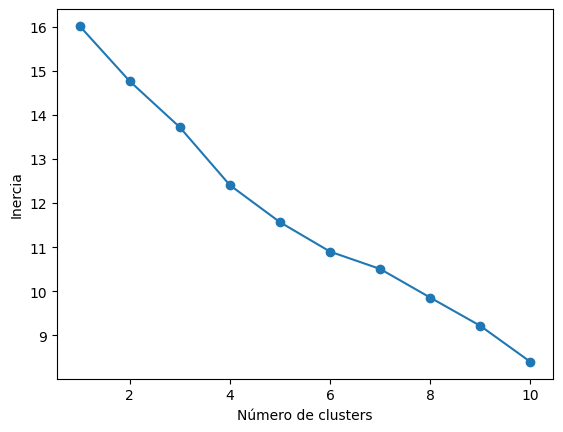

In [75]:
plt.plot(
    range(1,11),
    inercias,
    marker="o"
)
plt.xlabel("Número de clusters")
plt.ylabel("Inercia")
plt.show()

# Centro del campo
embeddings.mean(axis=0)
La función .mean es nativa de los objetos tipo sentencemodel. Promedia una dimension n del "articulo" x respecto de la misma dimensión n del resto de artículos x+1, x+2, ...

Supone que hay un sólo centro.
Intenta responder a ¿Qué tienen todos en común? mientras que kmeans ¿Qué diferencias internas hay?

Etiqueta:
for i,tit in enumerate(df["title"]):
    plt.annotate(
        str(i),
        (coords[i,0],coords[i,1])
    )


c:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


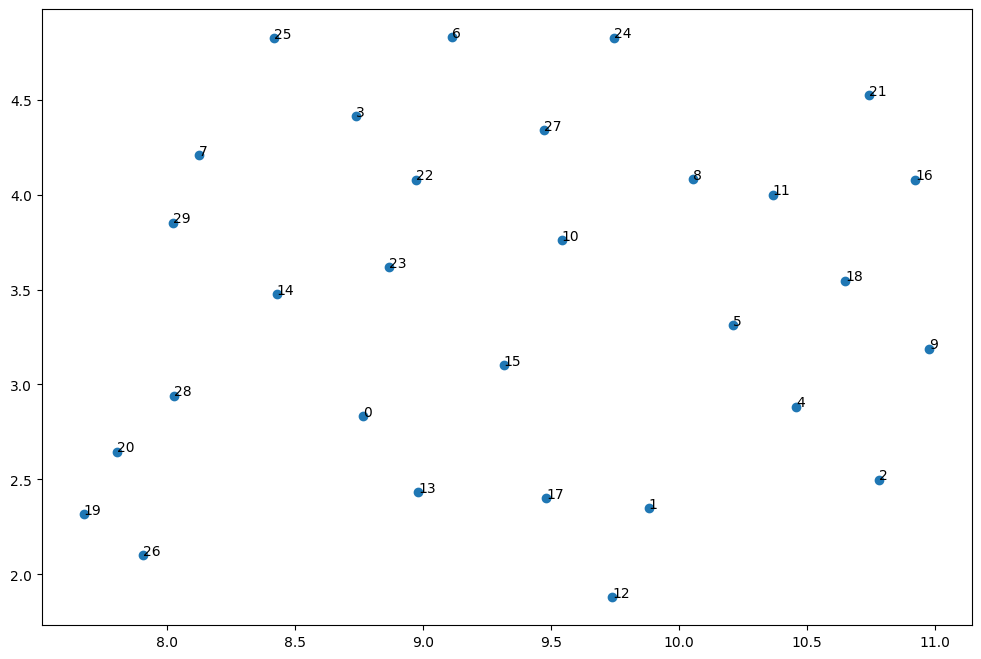

In [66]:
from sklearn.metrics.pairwise import cosine_similarity
import umap
from matplotlib import pyplot as plt
centro=embeddings.mean(axis=0)

sim_centro=cosine_similarity(embeddings,centro.reshape(1,-1))
reducer = umap.UMAP(
    random_state=42
)

coords = reducer.fit_transform(
    embeddings
)
#print(coords.shape)
plt.figure(figsize=(12,8))
plt.scatter(coords[:,0],coords[:,1])
for i,tit in enumerate(df["title"]):
    plt.annotate(
        str(i),
        (coords[i,0],coords[i,1])
    )
plt.show()

# Comprobaciones
- ¿Realmente hay estructura? Miramos la matriz de similitud par abuscar clusters.
    - Que sea homogeneo tiene sentido porque no estamos comparando con fisica cuántica, historia medieval, economía, contr explicabilidad.


## Matriz sim
Análisis de matriz de similitud.
- Mapa de calor de similitud por pares (pairwise similarity heatmap)
    - a0 a1 a2 ...
      a0
      a1
      a2
      ...
    - Cada celda es la similitud coseno entre (a0,a1)
- Es esperable observar una diagonal resaltada porque son los casos de similitud que se comparan consigo mismos.
- Se observan patrones de similitud no aleatorios aunque sin bloques perfectamente definidos.

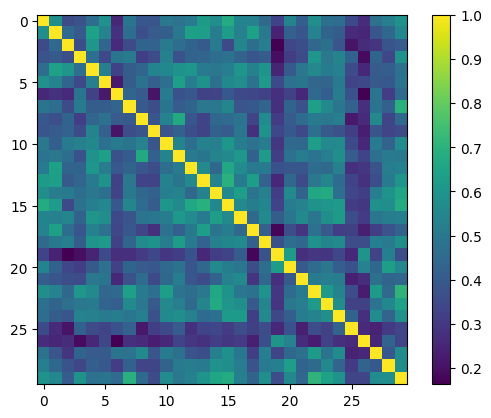

In [59]:
plt.imshow(sim)
plt.colorbar()
plt.show()

## Kmeans + UMAP

Identificar posibles agrupaciones temáticas en el corpus


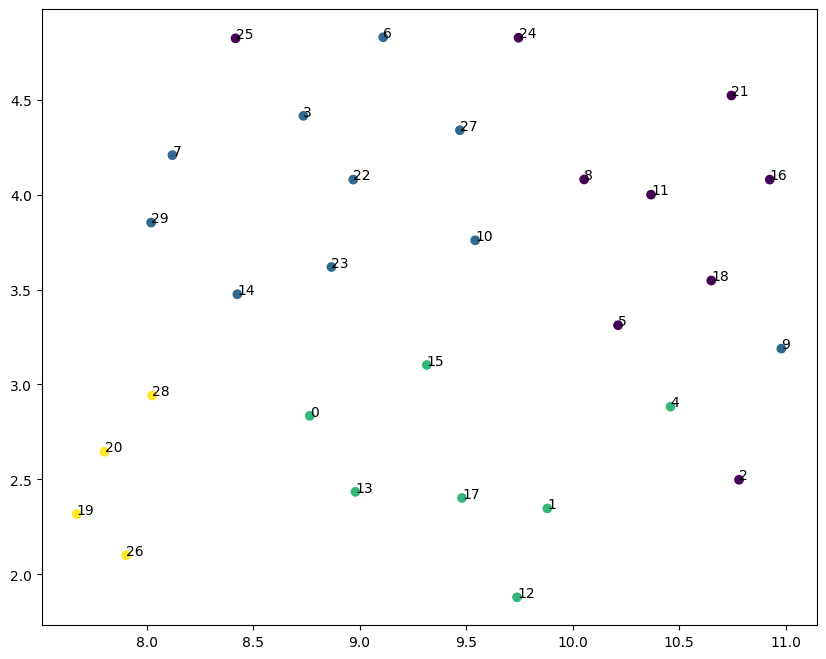

In [77]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42
)
labels = kmeans.fit_predict(embeddings)
plt.figure(figsize=(10,8))

plt.scatter(
    coords[:,0],
    coords[:,1],
    c=labels
)
for i,tit in enumerate(df["title"]):
    plt.annotate(
        str(i),
        (coords[i,0],coords[i,1])
    )

plt.show()

In [62]:
reducer = umap.UMAP(
    n_neighbors=5,
    min_dist=0.1,
    random_state=42
)
coords = reducer.fit_transform(
    embeddings
)
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.5,
    random_state=42
)

c:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


# Buscador semántico

In [88]:
query=model.encode("causal explanation methods")
score=cosine_similarity([query],embeddings)[0]
#print(score.shape)
reducer = umap.UMAP(
    random_state=42
)
indices = np.argsort(score)[::-1]

for i in indices[:10]:
    print(round(score[i],3))
    print(df.iloc[i]["title"])
    print()


0.472
Measuring Causal Effects of Data Statistics on Language Model's `Factual' Predictions

0.419
Right for the Right Reasons: Training Differentiable Models by Constraining their Explanations

0.415
e-SNLI: Natural Language Inference with Natural Language Explanations

0.406
Causal Analysis of Syntactic Agreement Mechanisms in Neural Language Models

0.382
Challenges in Applying Explainability Methods to Improve the Fairness of NLP Models

0.378
"Why Should I Trust You?": Explaining the Predictions of Any Classifier

0.368
Amnesic Probing: Behavioral Explanation with Amnesic Counterfactuals

0.354
CausaLM: Causal Model Explanation Through Counterfactual Language Models

0.347
Explaining non-linear Classifier Decisions within Kernel-based Deep Architectures

0.342
Evaluating neural network explanation methods using hybrid documents and morphosyntactic agreement



## Colorear query

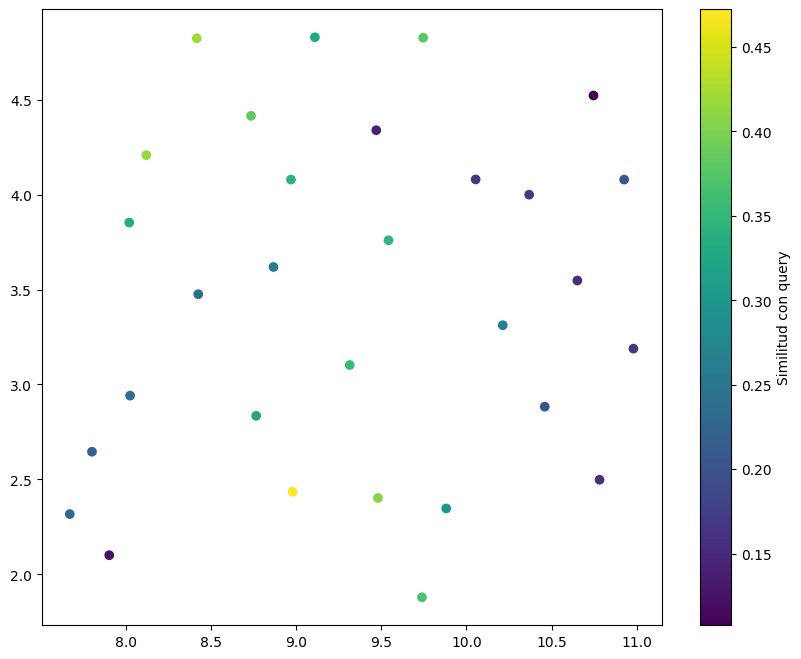

In [89]:
plt.figure(figsize=(10,8))

plt.scatter(
    coords[:,0],
    coords[:,1],
    c=score
)

plt.colorbar(label="Similitud con query")

plt.show()

## Dibujar query

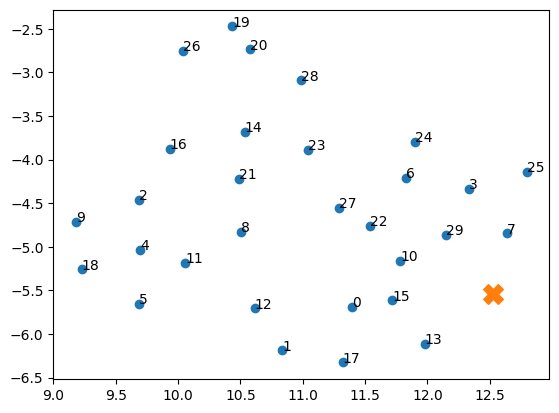

In [97]:
query = model.encode(
    "causal explanation methods"
)
todos = np.vstack([ # Agregas temporalmente el embedding de la query con el de la bibliografía
    embeddings,
    query
])
coords = reducer.fit_transform(todos)
coords.shape

plt.scatter(
    coords[:-1,0],
    coords[:-1,1]
)

plt.scatter(
    coords[-1,0],
    coords[-1,1],
    marker="X",
    s=200
)
for i,tit in enumerate(df["title"]):
    plt.annotate(
        str(i),
        (coords[i,0],coords[i,1])
    )
plt.show()